# Angle's Basic Wealth-Distribution Model

This simulates John Angle's **Inequality Process**, plots agent wealth through time, estimates a possible transient period, examines the final wealth distribution as a normalized probability density function (PDF), and compares the basic model with a clearly labeled modified model.

## Model summary

- At each pairwise encounter, the wealthier agent wins with probability `delta` (ties are resolved with probability 1/2).
- The loser transfers a fraction `omega` of their wealth to the winner in the basic model.
- Total wealth is conserved because every transfer is internal to the population.
- One **sweep** is defined here as `N` random pairwise encounters.
- The extension protects a subsistence reserve `s` and transfers only `omega * max(wealth - s, 0)` from the loser. This is a modeling extension motivated by Angle's discussion of subsistence wealth, not the exact original rule.

References:

1. Angle, J. (1993). “Deriving the size distribution of personal wealth from ‘the rich get richer, the poor get poorer’.” *Journal of Mathematical Sociology*, 18(1), 27–46. https://doi.org/10.1080/0022250X.1993.9990114
2. Angle, J. (1986). “The Surplus Theory of Social Stratification and the Size Distribution of Personal Wealth.” *Social Forces*, 65(2), 293–326.


## Define the model

The following cells define the simulation, diagnostics, plotting functions, CSV export, and report generation.

In [17]:
from __future__ import annotations

import argparse
import csv
from dataclasses import dataclass
from pathlib import Path
from typing import Optional

import matplotlib.pyplot as plt
import numpy as np


@dataclass
class SimulationResult:
    name: str
    wealth: np.ndarray
    tracked_history: np.ndarray
    gini_history: np.ndarray
    cv_history: np.ndarray
    mean_history: np.ndarray
    transient_estimate: Optional[int]
    tracked_ids: np.ndarray


def gini_coefficient(values: np.ndarray) -> float:
    """Compute the Gini coefficient for a nonnegative wealth vector."""
    x = np.asarray(values, dtype=float)
    x = np.sort(np.clip(x, 0.0, None))
    total = float(x.sum())
    if total <= 0.0:
        return 0.0
    n = x.size
    ranks = np.arange(1, n + 1, dtype=float)
    return float((2.0 * np.dot(ranks, x) / (n * total)) - (n + 1.0) / n)


def coefficient_of_variation(values: np.ndarray) -> float:
    """Return standard deviation divided by mean, using population SD."""
    mean = float(np.mean(values))
    if mean == 0.0:
        return 0.0
    return float(np.std(values) / mean)


def estimate_transient_time(
    gini_history: np.ndarray,
    cv_history: np.ndarray,
    window: int = 250,
    relative_tolerance: float = 0.08,
    consecutive_stable_comparisons: int = 3,
) -> Optional[int]:
    """
    The mean Gini and coefficient of variation in successive non-overlapping
    windows are compared. The transient estimate is the start of the first
    window in a run of stable windows.
    """
    length = min(len(gini_history), len(cv_history))
    if length < 2 * window:
        return None

    blocks = []
    for start in range(0, length - window + 1, window):
        stop = start + window
        blocks.append((
            start,
            float(np.mean(gini_history[start:stop])),
            float(np.mean(cv_history[start:stop])),
        ))

    stable = []
    for previous, current in zip(blocks[:-1], blocks[1:]):
        _, g0, c0 = previous
        _, g1, c1 = current
        g_change = abs(g1 - g0) / max(abs(g0), abs(g1), 0.05)
        c_change = abs(c1 - c0) / max(abs(c0), abs(c1), 0.05)
        stable.append(g_change <= relative_tolerance and c_change <= relative_tolerance)

    run = max(1, consecutive_stable_comparisons)
    for idx in range(0, len(stable) - run + 1):
        if all(stable[idx:idx + run]):
            # First block after the last observed change in this stable run.
            return int(blocks[idx + 1][0])
    return None


def interact_pair(
    wealth: np.ndarray,
    i: int,
    j: int,
    rng: np.random.Generator,
    delta: float,
    omega: float,
    modified: bool = False,
    subsistence: float = 0.2,
) -> None:
    """Apply one wealth-conserving pairwise encounter in place."""
    wi = float(wealth[i])
    wj = float(wealth[j])

    if wi > wj:
        i_wins_probability = delta
    elif wi < wj:
        i_wins_probability = 1.0 - delta
    else:
        i_wins_probability = 0.5

    if rng.random() < i_wins_probability:
        winner, loser = i, j
    else:
        winner, loser = j, i

    loser_wealth = float(wealth[loser])
    if modified:
        # Protect the subsistence reserve; only the surplus can be transferred.
        transferable = max(loser_wealth - subsistence, 0.0)
        transfer = omega * transferable
    else:
        transfer = omega * loser_wealth

    wealth[loser] -= transfer
    wealth[winner] += transfer

    # Remove harmless round-off drift near zero, without changing meaningful
    # values. The transfer rules above should never create negative wealth.
    if wealth[loser] < 0.0 and wealth[loser] > -1e-12:
        wealth[loser] = 0.0


def simulate(
    *,
    name: str,
    n_agents: int,
    n_sweeps: int,
    delta: float,
    omega: float,
    seed: int,
    track_agents: int,
    modified: bool = False,
    subsistence: float = 0.2,
    transient_window: int = 250,
    transient_tolerance: float = 0.08,
) -> SimulationResult:
    """Run the chosen model and store diagnostics after every sweep."""
    rng = np.random.default_rng(seed)
    # Equal starting wealth makes the emergence of inequality easy to see.
    wealth = np.ones(n_agents, dtype=float)
    initial_total = float(wealth.sum())
    tracked_ids = np.arange(min(track_agents, n_agents), dtype=int)

    tracked_history = np.empty((n_sweeps + 1, tracked_ids.size), dtype=float)
    gini_history = np.empty(n_sweeps + 1, dtype=float)
    cv_history = np.empty(n_sweeps + 1, dtype=float)
    mean_history = np.empty(n_sweeps + 1, dtype=float)

    def record(step: int) -> None:
        tracked_history[step] = wealth[tracked_ids]
        gini_history[step] = gini_coefficient(wealth)
        cv_history[step] = coefficient_of_variation(wealth)
        mean_history[step] = float(np.mean(wealth))

    record(0)
    for sweep in range(1, n_sweeps + 1):
        # One sweep consists of N encounters. Pick distinct agents uniformly.
        for _ in range(n_agents):
            i = int(rng.integers(n_agents))
            j = int(rng.integers(n_agents - 1))
            if j >= i:
                j += 1
            interact_pair(
                wealth, i, j, rng, delta, omega,
                modified=modified, subsistence=subsistence,
            )
        record(sweep)

    final_total = float(wealth.sum())
    if not np.isclose(initial_total, final_total, rtol=1e-10, atol=1e-10):
        raise RuntimeError(
            f"Wealth conservation check failed for {name}: "
            f"initial={initial_total}, final={final_total}"
        )
    if np.min(wealth) < -1e-10:
        raise RuntimeError(f"Negative wealth detected in {name} simulation")

    transient = estimate_transient_time(
        gini_history,
        cv_history,
        window=transient_window,
        relative_tolerance=transient_tolerance,
        consecutive_stable_comparisons=3,
    )

    return SimulationResult(
        name=name,
        wealth=wealth.copy(),
        tracked_history=tracked_history,
        gini_history=gini_history,
        cv_history=cv_history,
        mean_history=mean_history,
        transient_estimate=transient,
        tracked_ids=tracked_ids,
    )

In [18]:
def distribution_skewness(values: np.ndarray) -> float:
    """Compute the standardized third central moment."""
    x = np.asarray(values, dtype=float)
    sd = float(np.std(x))
    if sd == 0.0:
        return 0.0
    return float(np.mean(((x - np.mean(x)) / sd) ** 3))


def top_share(values: np.ndarray, fraction: float = 0.10) -> float:
    """Return the fraction of total wealth held by the richest given fraction."""
    x = np.sort(np.asarray(values, dtype=float))
    count = max(1, int(np.ceil(fraction * len(x))))
    total = float(x.sum())
    return float(x[-count:].sum() / total) if total > 0 else 0.0


def plot_trajectory(
    result: SimulationResult,
    max_step: int,
    title_suffix: str,
    transient_line: Optional[int] = None,
    start_step: int = 0,
) -> None:
    """Plot wealth histories for the tracked agents over a selected interval."""
    final_step = result.tracked_history.shape[0] - 1
    start_step = max(0, min(start_step, final_step))
    end_step = max(start_step, min(max_step, final_step))
    if end_step <= start_step:
        start_step = 0
        end_step = final_step
    steps = np.arange(start_step, end_step + 1)

    fig, ax = plt.subplots(figsize=(13, 5))
    for column, agent_id in enumerate(result.tracked_ids):
        ax.plot(
            steps,
            result.tracked_history[start_step:end_step + 1, column],
            linewidth=1.0,
            alpha=0.85,
            label=f"Agent {agent_id + 1}",
        )
    if transient_line is not None and start_step <= transient_line <= end_step:
        ax.axvline(
            transient_line,
            color="black",
            linestyle="--",
            linewidth=1.2,
            label=f"Estimated transient: {transient_line}",
        )
    ax.set_xlabel("Iteration (one sweep = N pairwise encounters)")
    ax.set_ylabel("Wealth")
    ax.set_title(f"{result.name}: wealth trajectories {title_suffix}")
    ax.grid(True, alpha=0.25)
    ax.legend(ncol=3, fontsize=8, frameon=False)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


def plot_diagnostics(
    result: SimulationResult,
    transient_line: Optional[int],
) -> None:
    steps = np.arange(result.gini_history.size)
    fig, axes = plt.subplots(2, 1, figsize=(13, 10), sharex=True)
    axes[0].plot(steps, result.gini_history, linewidth=0.9)
    axes[0].set_ylabel("Gini coefficient")
    axes[0].grid(True, alpha=0.25)
    axes[1].plot(steps, result.cv_history, linewidth=0.9)
    axes[1].set_ylabel("Coefficient of variation")
    axes[1].set_xlabel("Iteration (one sweep = N pairwise encounters)")
    axes[1].grid(True, alpha=0.25)
    if transient_line is not None:
        for ax in axes:
            ax.axvline(transient_line, color="black", linestyle="--", linewidth=1.2)
    fig.suptitle(f"{result.name}: distribution-shape diagnostics")
    fig.tight_layout()
    plt.show()
    plt.close(fig)


def plot_final_pdf(result: SimulationResult) -> None:
    fig, ax = plt.subplots(figsize=(13, 5))
    # density=True normalizes the histogram to integrate to approximately one.
    ax.hist(result.wealth, bins="sqrt", density=True, alpha=0.75, edgecolor="black")
    ax.axvline(float(np.mean(result.wealth)), color="black", linestyle="--",
               linewidth=1.3, label=f"Mean = {np.mean(result.wealth):.3f}")
    ax.set_xlabel("Final wealth")
    ax.set_ylabel("Probability density (PDF)")
    ax.set_title("Angle's basic model: final wealth distribution (normalized PDF)")
    ax.grid(True, axis="y", alpha=0.25)
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


def plot_pdf_comparison(
    basic: SimulationResult,
    modified: SimulationResult,
) -> None:
    combined = np.concatenate((basic.wealth, modified.wealth))
    bins = np.histogram_bin_edges(combined, bins="sqrt")
    fig, ax = plt.subplots(figsize=(13, 5))
    ax.hist(basic.wealth, bins=bins, density=True, alpha=0.55,
            edgecolor="black", label="Basic model")
    ax.hist(modified.wealth, bins=bins, density=True, alpha=0.5,
            edgecolor="black", label="Modified: protected subsistence")
    ax.set_xlabel("Final wealth")
    ax.set_ylabel("Probability density (PDF)")
    ax.set_title("Final wealth distribution: basic vs. modified model")
    ax.grid(True, axis="y", alpha=0.25)
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


def export_timeseries_csv(result: SimulationResult, output_dir: Path) -> None:
    path = output_dir / f"{result.name.lower().replace(' ', '_')}_timeseries.csv"
    with path.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.writer(handle)
        writer.writerow(
            ["sweep", "mean_wealth", "gini", "coefficient_of_variation"]
            + [f"agent_{agent_id + 1}_wealth" for agent_id in result.tracked_ids]
        )
        for t in range(result.mean_history.size):
            writer.writerow([
                t,
                f"{result.mean_history[t]:.10f}",
                f"{result.gini_history[t]:.10f}",
                f"{result.cv_history[t]:.10f}",
                *[f"{v:.10f}" for v in result.tracked_history[t]],
            ])


def format_result(result: SimulationResult, n_agents: int, n_sweeps: int) -> str:
    final = result.wealth
    lines = [
        f"{result.name}",
        "-" * 50,
        f"Agents: {n_agents}; sweeps: {n_sweeps}; tracked agents: {len(result.tracked_ids)}",
        f"Initial mean wealth: 1.000000; final mean wealth: {np.mean(final):.6f}",
        f"Final minimum / median / maximum: {np.min(final):.6f} / "
        f"{np.median(final):.6f} / {np.max(final):.6f}",
        f"Final Gini coefficient: {gini_coefficient(final):.4f}",
        f"Final coefficient of variation: {coefficient_of_variation(final):.4f}",
        f"Final standardized skewness: {distribution_skewness(final):.4f}",
        f"Share of total wealth held by richest 10%: {100 * top_share(final):.2f}%",
    ]
    if result.transient_estimate is None:
        lines.append(
            "Transient diagnostic: no stable-window run was detected with the "
            "configured Gini/CV criteria. Do not report a confirmed transient; "
            "increase T or inspect the diagnostic plot."
        )
    else:
        remaining = n_sweeps - result.transient_estimate
        lines.append(
            f"Heuristic transient estimate: about {result.transient_estimate} sweeps; "
            f"{remaining} sweeps remain after that point."
        )
    if result.transient_estimate is not None and n_sweeps - result.transient_estimate >= 1000:
        lines.append(
            "KR3 check: at least 1,000 sweeps are available after the estimated "
            "transient for the post-transient trajectory plot."
        )
    elif result.transient_estimate is not None:
        lines.append(
            "KR3 warning: fewer than 1,000 sweeps remain after the estimated "
            "transient. Increase --T before using this run for KR3."
        )
    lines.append("")
    return "\n".join(lines)



## Set simulation parameters

The defaults use at least 100 agents and enough sweeps to allow a long series after a detected transient. Increase `T` for longer runs. `seed` makes the results reproducible.

In [19]:
# Configuration: edit these values as needed.
N = 200                 # Number of agents (must be >= 100)
T = 10_000              # Number of sweeps
DELTA = 0.65            # Probability richer agent wins (0.5 < DELTA < 1)
OMEGA = 0.20             # Fraction of loser's wealth transferred in basic model
SUBSISTENCE = 0.20       # Protected reserve in the modified model
SEED = 42                # Random seed for reproducibility
TRACK_AGENTS = 12        # Number of agents to plot (must be >= 10)
TRANSIENT_WINDOW = 250   # Window size used by transient diagnostic
TRANSIENT_TOLERANCE = 0.08
OUTPUT_DIR = Path("angle_model_output")

# Basic parameter checks.
if N < 100:
    raise ValueError("N must be at least 100 agents.")
if T < 1500:
    raise ValueError("T must be at least 1500 sweeps to allow transient analysis.")
if not (0.5 < DELTA < 1.0):
    raise ValueError("DELTA must be greater than 0.5 and less than 1.")
if not (0.0 < OMEGA <= 1.0):
    raise ValueError("OMEGA must be in (0, 1].")
if not (0.0 <= SUBSISTENCE < 1.0):
    raise ValueError("SUBSISTENCE must be at least 0 and below the initial wealth (1.0).")
if TRACK_AGENTS < 10:
    raise ValueError("TRACK_AGENTS must be at least 10.")
if TRANSIENT_WINDOW < 25:
    raise ValueError("TRANSIENT_WINDOW must be at least 25.")
if TRANSIENT_TOLERANCE <= 0.0:
    raise ValueError("TRANSIENT_TOLERANCE must be positive.")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TRACKED_COUNT = min(TRACK_AGENTS, N)
print(f"N={N}, T={T}, delta={DELTA}, omega={OMEGA}, seed={SEED}")
print(f"Output directory: {OUTPUT_DIR.resolve()}")

N=200, T=10000, delta=0.65, omega=0.2, seed=42
Output directory: C:\Users\ermag\Desktop\VSC\AP195\M04\angle_model_output


## Run the basic and modified models

In [20]:
print("Running Angle's basic Inequality Process...")
basic = simulate(
    name="Basic model",
    n_agents=N,
    n_sweeps=T,
    delta=DELTA,
    omega=OMEGA,
    seed=SEED,
    track_agents=TRACKED_COUNT,
    modified=False,
    transient_window=TRANSIENT_WINDOW,
    transient_tolerance=TRANSIENT_TOLERANCE,
)

print("Running protected-subsistence modification...")
modified = simulate(
    name="Modified model",
    n_agents=N,
    n_sweeps=T,
    delta=DELTA,
    omega=OMEGA,
    seed=SEED + 1,
    track_agents=TRACKED_COUNT,
    modified=True,
    subsistence=SUBSISTENCE,
    transient_window=TRANSIENT_WINDOW,
    transient_tolerance=TRANSIENT_TOLERANCE,
)

print("Both simulations completed. Wealth conservation checks passed.")

Running Angle's basic Inequality Process...
Running protected-subsistence modification...
Both simulations completed. Wealth conservation checks passed.


## Generate figures and data tables


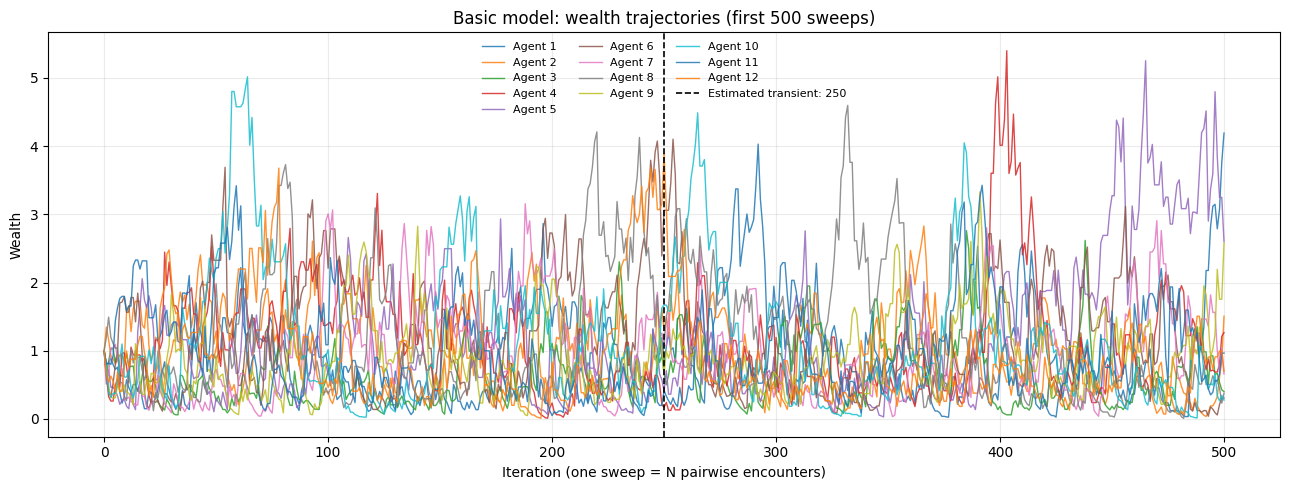

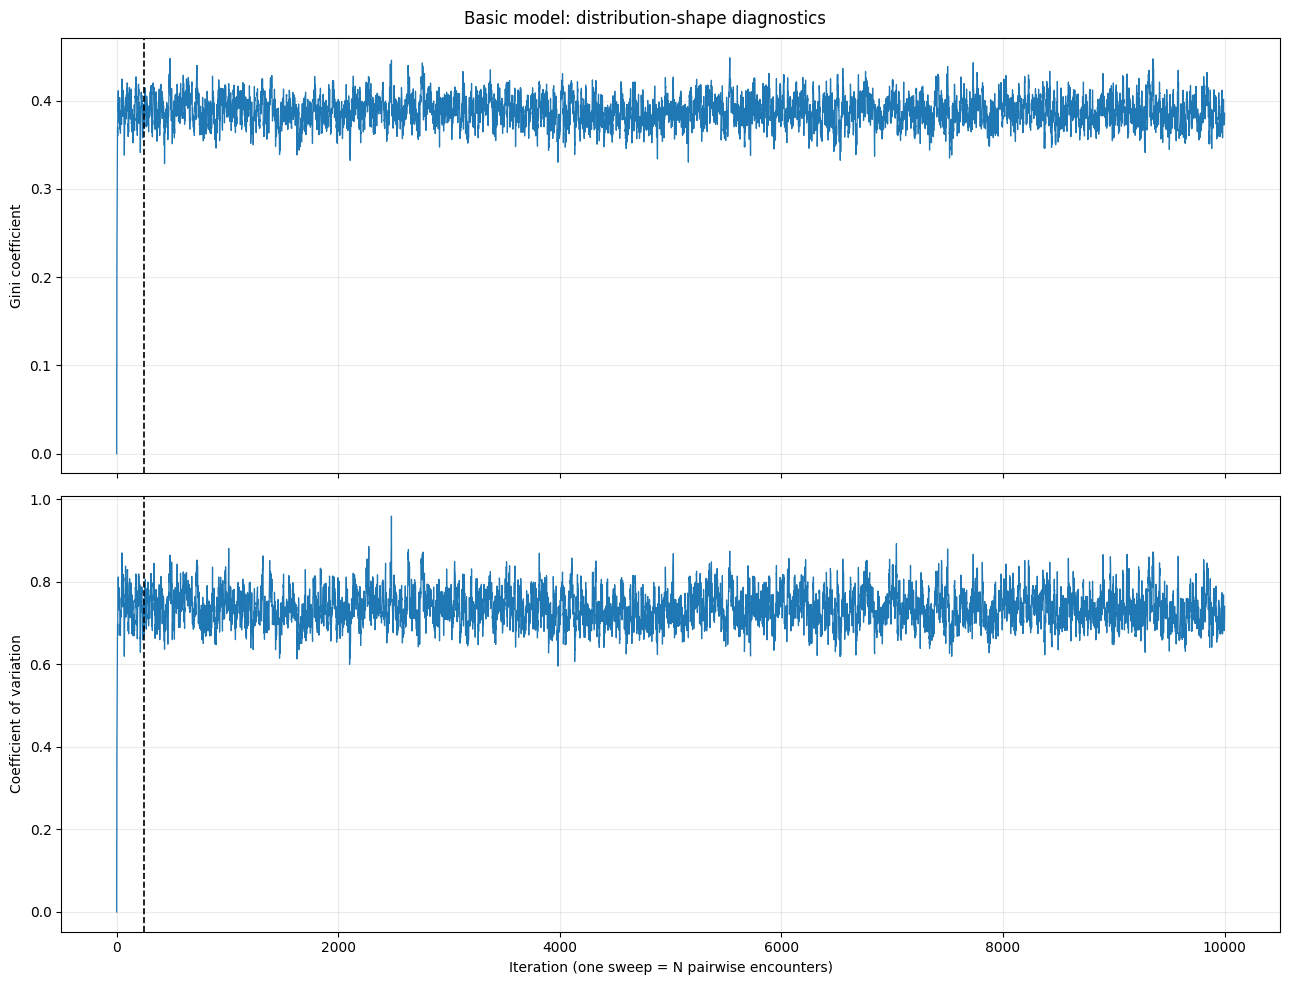

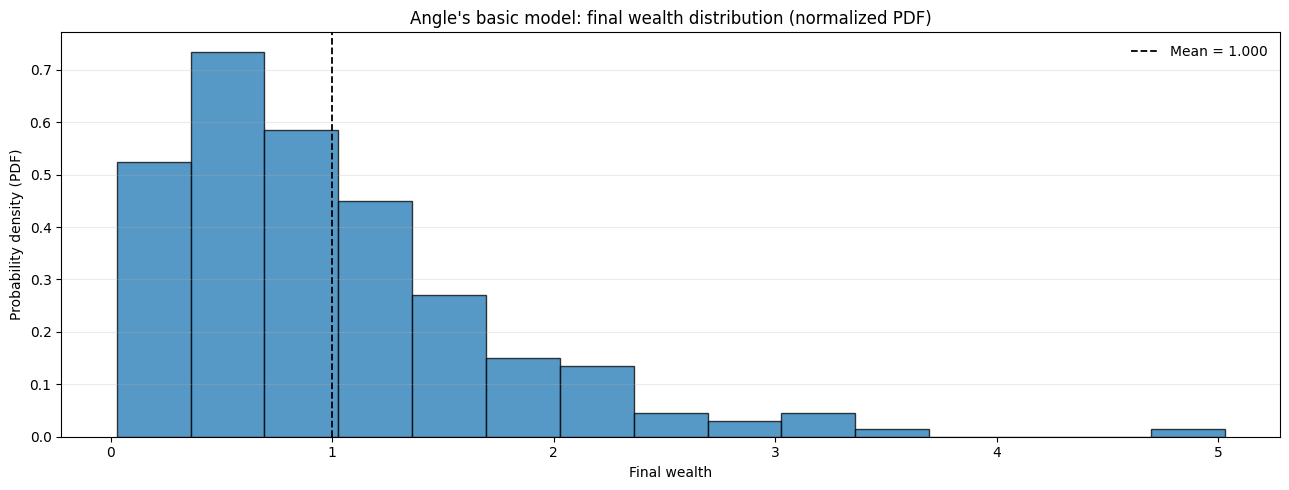

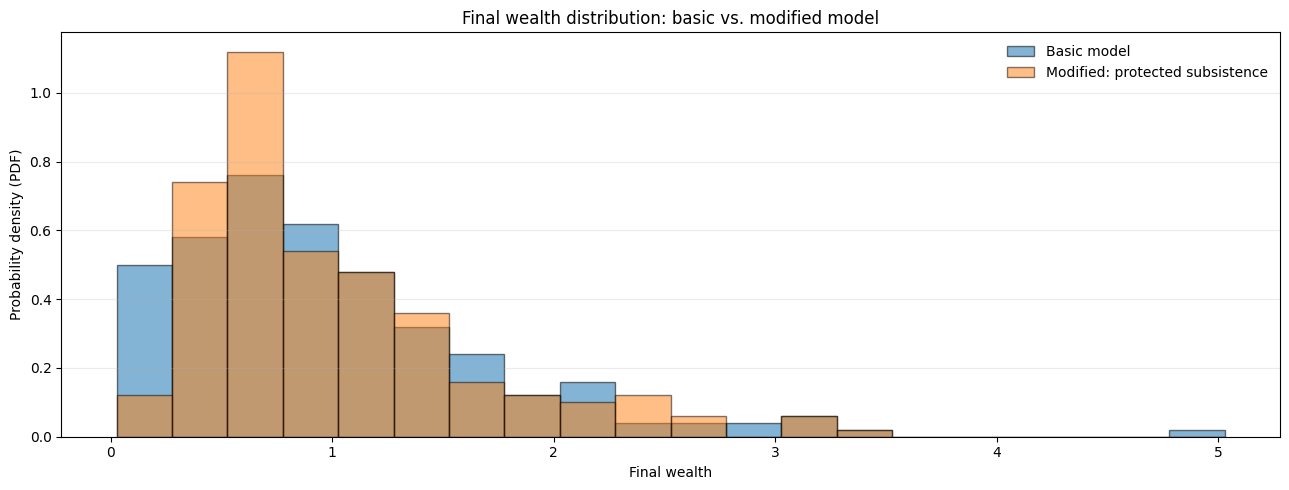

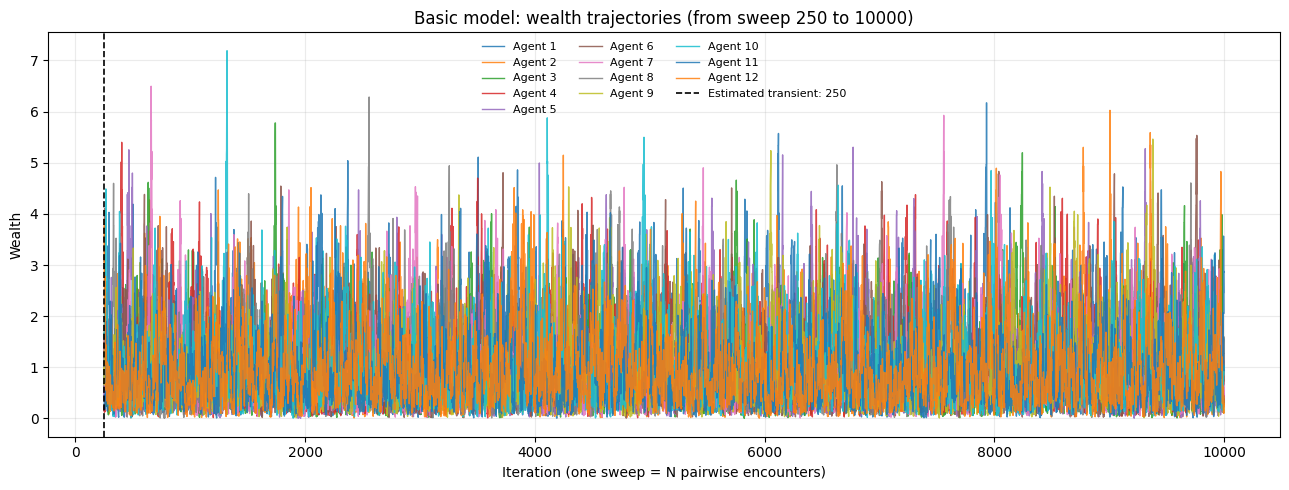

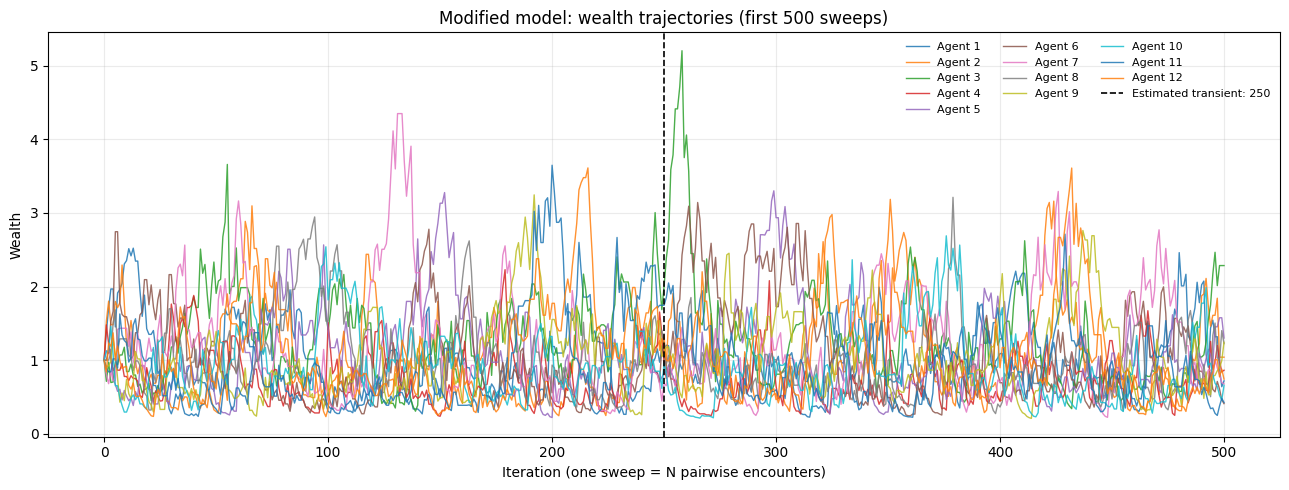


BASIC MODEL SUMMARY
Basic model
--------------------------------------------------
Agents: 200; sweeps: 10000; tracked agents: 12
Initial mean wealth: 1.000000; final mean wealth: 1.000000
Final minimum / median / maximum: 0.027648 / 0.817590 / 5.029562
Final Gini coefficient: 0.3858
Final coefficient of variation: 0.7408
Final standardized skewness: 1.6469
Share of total wealth held by richest 10%: 26.30%
Heuristic transient estimate: about 250 sweeps; 9750 sweeps remain after that point.
KR3 check: at least 1,000 sweeps are available after the estimated transient for the post-transient trajectory plot.

MODIFIED MODEL SUMMARY
Modified model
--------------------------------------------------
Agents: 200; sweeps: 10000; tracked agents: 12
Initial mean wealth: 1.000000; final mean wealth: 1.000000
Final minimum / median / maximum: 0.222380 / 0.793239 / 3.327326
Final Gini coefficient: 0.3301
Final coefficient of variation: 0.6345
Final standardized skewness: 1.4576
Share of total wealt

In [21]:
first_window_end = min(500, T)

plot_trajectory(
    basic, max_step=first_window_end,
    title_suffix=f"(first {first_window_end} sweeps)",
    transient_line=basic.transient_estimate,
    start_step=0,
)
plot_diagnostics(basic, basic.transient_estimate)
plot_final_pdf(basic)
plot_pdf_comparison(basic, modified)
export_timeseries_csv(basic, OUTPUT_DIR)
export_timeseries_csv(modified, OUTPUT_DIR)

if basic.transient_estimate is not None:
    post_start = basic.transient_estimate
else:
    # Fallback is a chosen burn-in for visualization, not a detected transient.
    post_start = min(1000, T - 1000)

plot_trajectory(
    basic, max_step=T,
    title_suffix=f"(from sweep {post_start} to {T})",
    transient_line=basic.transient_estimate,
    start_step=post_start,
)
plot_trajectory(
    modified, max_step=first_window_end,
    title_suffix=f"(first {first_window_end} sweeps)",
    transient_line=modified.transient_estimate,
    start_step=0,
)

print("\nBASIC MODEL SUMMARY")
print("="*50)
print(format_result(basic, N, T))
print("MODIFIED MODEL SUMMARY")
print("="*50)
print(format_result(modified, N, T))
print(f"\nSaved outputs to: {OUTPUT_DIR.resolve()}")
if basic.transient_estimate is None:
    print("NOTE: transient was not detected by the heuristic; inspect diagnostics and increase T if needed.")
elif T - basic.transient_estimate < 1000:
    print("WARNING: fewer than 1,000 sweeps remain after the estimated transient. Increase T for KR3.")